In [11]:
# Problem 1(c)
import numpy as np

import os
import matplotlib.pyplot as plt
import pandas as pd

for m in range(3, 13):
    # Construct the transition matrix
    P = np.zeros((m, m))

    for i in range(m - 1):
        P[i, i + 1] = 1.0

    P[m - 1, 0] = 0.5
    P[m - 1, 1] = 0.5

    # Boolean matrix for possible paths of length zero
    B = np.eye(m, dtype=bool)
    A = (P > 0)
    M = 0

    # Find the smallest M such that P^M is strictly positive
    while not np.all(B):
        B = (
            B.astype(int) @ A.astype(int)
        ) > 0
        M += 1

    # Sort eigenvalues by modulus
    eigenvalues = np.linalg.eigvals(P)
    moduli = np.sort(np.abs(eigenvalues))[::-1]
    lambda2 = moduli[1]

    bound = (m - 1)**2 + 1
    gap = 1 - lambda2

    print(
        f"m={m:2d}, M={M:3d}, "
        f"bound={bound:3d}, "
        f"|lambda2|={lambda2:.9f}, "
        f"gap={gap:.9f}"
    )


m= 3, M=  5, bound=  5, |lambda2|=0.707106781, gap=0.292893219
m= 4, M= 10, bound= 10, |lambda2|=0.878546815, gap=0.121453185
m= 5, M= 17, bound= 17, |lambda2|=0.943122152, gap=0.056877848
m= 6, M= 26, bound= 26, |lambda2|=0.969192905, gap=0.030807095
m= 7, M= 37, bound= 37, |lambda2|=0.981496516, gap=0.018503484
m= 8, M= 50, bound= 50, |lambda2|=0.988029436, gap=0.011970564
m= 9, M= 65, bound= 65, |lambda2|=0.991813700, gap=0.008186300
m=10, M= 82, bound= 82, |lambda2|=0.994155782, gap=0.005844218
m=11, M=101, bound=101, |lambda2|=0.995682494, gap=0.004317506
m=12, M=122, bound=122, |lambda2|=0.996720112, gap=0.003279888


PRE-WEEKEND RESULTS (predict winner by higher r_i)

Flat: lambda*=0.499233, |lambda2/lambda*|=0.158985
BYU vs Iowa State: predicted BYU; actual BYU; CORRECT
Oklahoma State vs UCF: predicted Oklahoma State; actual Oklahoma State; CORRECT
Kansas State vs Houston: predicted Houston; actual Houston; CORRECT
Utah vs Kansas: predicted Utah; actual Utah; CORRECT
West Virginia vs Arizona: predicted Arizona; actual Arizona; CORRECT

2025 meetings: lambda*=0.481875, |lambda2/lambda*|=0.159949
BYU vs Iowa State: predicted BYU; actual BYU; CORRECT
Oklahoma State vs UCF: predicted UCF; actual Oklahoma State; WRONG
Kansas State vs Houston: predicted Houston; actual Houston; CORRECT
Utah vs Kansas: predicted Utah; actual Utah; CORRECT
West Virginia vs Arizona: predicted Arizona; actual Arizona; CORRECT

2025 wins + 1: lambda*=0.465951, |lambda2/lambda*|=0.170211
BYU vs Iowa State: predicted BYU; actual BYU; CORRECT
Oklahoma State vs UCF: predicted UCF; actual Oklahoma State; WRONG
Kansas State vs Hou

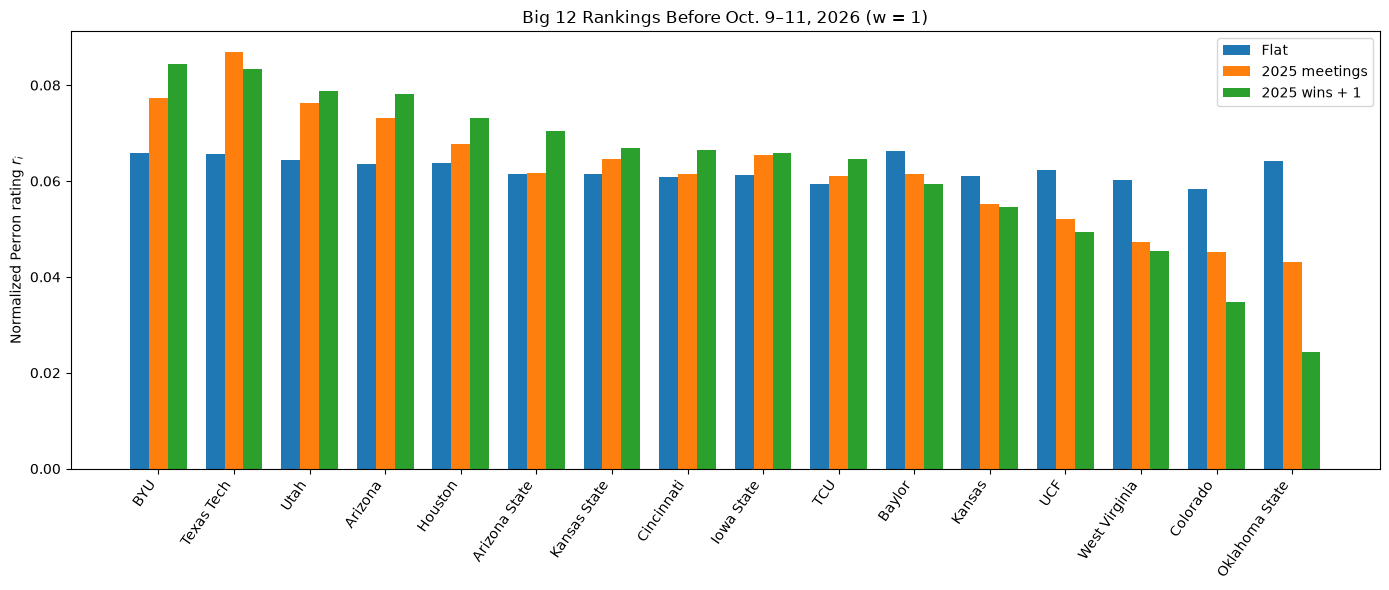

In [12]:
# Problem 2(c): 
import numpy as np
import os
import matplotlib.pyplot as plt
import pandas as pd

CSV = "big12.csv"
W = 1.0
df = pd.read_csv(CSV)
teams = sorted(set(df["home"]) | set(df["away"]))
m = len(teams)
ix = {team: i for i, team in enumerate(teams)}

def h_score(S, T):
    x = (S + 1) / (S + T + 2)
    z = x - 0.5
    sign = 0 if z == 0 else (1 if z > 0 else -1)
    return 0.5 + 0.5 * sign * np.sqrt(abs(2 * x - 1))

# Prior 1: flat prior, Pi_ij = 1/2.
# Prior 2: mean 2025 h-values in games between i and j; 1/2 if no meeting.
# Prior 3 (our own): smoothed 2025 conference win totals, s_i = wins_i + 1,
# Pi_ij = s_i/(s_i+s_j).
past = df[(df.season == 2025) & (df.completed == 1)]
pair_h = {}
wins = {t: 0 for t in teams}
for g in past.itertuples():
    H, A = g.home, g.away
    S, T = int(g.home_pts), int(g.away_pts)
    pair_h.setdefault((H, A), []).append(h_score(S, T))
    pair_h.setdefault((A, H), []).append(h_score(T, S))
    if S > T:
        wins[H] += 1
    elif T > S:
        wins[A] += 1

def prior(kind):
    P = np.full((m, m), 0.5)
    for i, ti in enumerate(teams):
        for j, tj in enumerate(teams):
            if i == j:
                continue
            if kind == "flat":
                P[i, j] = 0.5
            elif kind == "last":
                values = pair_h.get((ti, tj), [])
                P[i, j] = float(np.mean(values)) if values else 0.5
            elif kind == "custom":
                si, sj = wins[ti] + 1, wins[tj] + 1
                P[i, j] = si / (si + sj)
    return P

def rank(games, kind):
    P = prior(kind)
    A = np.zeros((m, m))
    n = np.zeros(m)
    for g in games.itertuples():
        if int(g.completed) != 1:
            continue
        i, j = ix[g.home], ix[g.away]
        S, T = int(g.home_pts), int(g.away_pts)
        A[i, j] += h_score(S, T)
        A[j, i] += h_score(T, S)
        n[i] += 1
        n[j] += 1
    # Apply a_ij = (sum h_ij + w Pi_ij)/(n_i + w(m-1)); a_ii = 0.
    for i in range(m):
        for j in range(m):
            if i != j:
                A[i, j] = (A[i, j] + W * P[i, j]) / (n[i] + W * (m - 1))
    eigvals, eigvecs = np.linalg.eig(A)
    order = np.argsort(np.abs(eigvals))[::-1]
    lam = float(eigvals[order[0]].real)
    r = np.abs(eigvecs[:, order[0]].real)
    r = r / r.sum()
    ratio = float(abs(eigvals[order[1]]) / abs(eigvals[order[0]]))
    return lam, ratio, r

# Freeze information before the Oct. 9-10 weekend to make honest predictions.
pre = df[(df.season == 2026) & (df.date < "2026-10-09")].copy()
# Results from Oct. 9-10, 2026, used only after predictions are recorded.
weekend = pd.DataFrame([
    (2026, 6, "2026-10-09", "BYU", 24, "Iowa State", 10, 0, 1),
    (2026, 6, "2026-10-10", "Oklahoma State", 42, "UCF", 28, 0, 1),
    (2026, 6, "2026-10-10", "Kansas State", 16, "Houston", 35, 0, 1),
    (2026, 6, "2026-10-10", "Utah", 41, "Kansas", 24, 0, 1),
    (2026, 6, "2026-10-10", "West Virginia", 31, "Arizona", 52, 0, 1),
], columns=df.columns)

kinds = ["flat", "last", "custom"]
labels = {"flat": "Flat", "last": "2025 meetings", "custom": "2025 wins + 1"}
pre_r = {}
print("PRE-WEEKEND RESULTS (predict winner by higher r_i)")
for kind in kinds:
    lam, ratio, r = rank(pre, kind)
    pre_r[kind] = r
    print(f"\n{labels[kind]}: lambda*={lam:.6f}, |lambda2/lambda*|={ratio:.6f}")
    for g in weekend.itertuples():
        predicted = g.home if r[ix[g.home]] > r[ix[g.away]] else g.away
        actual = g.home if g.home_pts > g.away_pts else g.away
        print(f"{g.home} vs {g.away}: predicted {predicted}; actual {actual}; "
              f"{'CORRECT' if predicted == actual else 'WRONG'}")

# Bar chart of the three pre-weekend ranking vectors.
order = sorted(teams, key=lambda t: -pre_r["custom"][ix[t]])
x = np.arange(m)
width = 0.25
plt.figure(figsize=(14, 6))
for offset, kind in [(-width, "flat"), (0, "last"), (width, "custom")]:
    plt.bar(x + offset, [pre_r[kind][ix[t]] for t in order],
            width, label=labels[kind])
plt.xticks(x, order, rotation=55, ha="right")
plt.ylabel("Normalized Perron rating $r_i$")
plt.title("Big 12 Rankings Before Oct. 9–11, 2026 (w = 1)")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.expanduser("~/Downloads/Problem 2.pdf"), bbox_inches="tight")

# Rerun rankings after adding the weekend results.
post = pd.concat([pre, weekend], ignore_index=True)
print("\nPOST-WEEKEND RANKINGS")
for kind in kinds:
    lam, ratio, r = rank(post, kind)
    ranking = sorted(teams, key=lambda t: -r[ix[t]])
    print(f"\n{labels[kind]}: lambda*={lam:.6f}, |lambda2/lambda*|={ratio:.6f}")
    print(" > ".join(f"{t} ({r[ix[t]]:.4f})" for t in ranking))


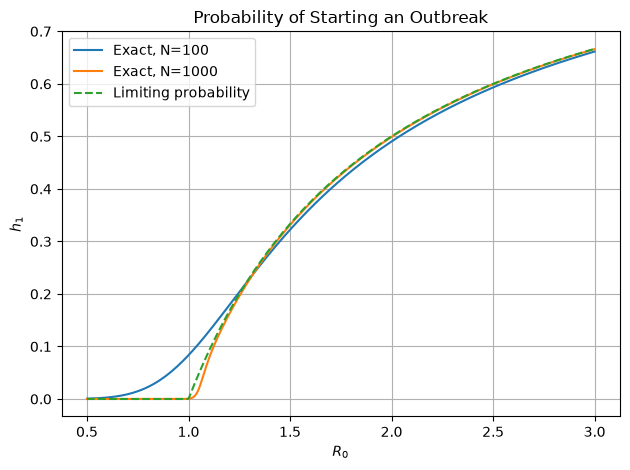

In [13]:
# Problem 3(c)
import numpy as np
import os
import matplotlib.pyplot as plt
import pandas as pd

def exact_h1(N, K, R0):
    rho = np.ones(K)
    for j in range(1, K):
        rho[j] = rho[j - 1] * N / (R0 * (N - j))
    return 1 / np.sum(rho)

R_values = np.linspace(0.5, 3.0, 400)

for N in [100, 1000]:
    K = N // 10
    h_values = [exact_h1(N, K, r) for r in R_values]
    plt.plot(R_values, h_values, label=f"Exact, N={N}")

plt.plot(R_values, np.maximum(0, 1 - 1/R_values),
         "--", label="Limiting probability")

plt.xlabel(r"$R_0$")
plt.ylabel(r"$h_1$")
plt.title("Probability of Starting an Outbreak")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.expanduser("~/Downloads/HW 6 Probelm 3 c.pdf"), bbox_inches="tight")

plt.show()


In [14]:
# Problem 3(d):
import numpy as np
import os
import matplotlib.pyplot as plt
import pandas as pd

def expected_time(N, K, R0, gamma=1.0):
    m = K - 1
    A = np.zeros((m, m))
    b = np.ones(m)

    for n in range(1, K):
        lam = (R0 * gamma / N) * n * (N - n)
        mu = gamma * n
        i = n - 1

        A[i, i] = lam + mu
        if n + 1 < K:
            A[i, i + 1] = -lam
        if n - 1 >= 1:
            A[i, i - 1] = -mu

    return np.linalg.solve(A, b)

N, K, gamma = 100, 10, 1.0

print("R0     e1 * dt")
for R0 in [0.5, 0.8, 1.5, 3.0]:
    tau = expected_time(N, K, R0, gamma)
    print(f"{R0:<5}  {tau[0]:.6f}")

# Check of independence from dt: solve the actual one-step system for each dt
def e_discrete(N, K, R0, dt, gamma=1.0):
    m = K - 1
    A = np.zeros((m, m)); b = np.ones(m)
    for n in range(1, K):
        p = (R0 * gamma / N) * n * (N - n) * dt
        q = gamma * n * dt
        i = n - 1
        A[i, i] = p + q
        if n + 1 < K: A[i, i + 1] = -p
        if n - 1 >= 1: A[i, i - 1] = -q
    return np.linalg.solve(A, b)

for dt in [0.005, 0.0005]:
    print(f"dt={dt}: e1*dt = {e_discrete(100, 10, 1.5, dt)[0] * dt:.6f}")


R0     e1 * dt
0.5    1.373575
0.8    1.769876
1.5    1.795853
3.0    0.965486
dt=0.005: e1*dt = 1.795853
dt=0.0005: e1*dt = 1.795853


In [15]:
# Problem 3(d):
import numpy as np
import os
import matplotlib.pyplot as plt
import pandas as pd

def simulate(N, K, R0, gamma, dt, trials=100_000, seed=42):
    rng = np.random.default_rng(seed)
    x = np.ones(trials, dtype=int)
    steps = np.zeros(trials, dtype=int)
    active = np.ones(trials, dtype=bool)
    beta = R0 * gamma / N

    while np.any(active):
        idx = np.flatnonzero(active)
        n = x[idx]
        p = beta * n * (N - n) * dt
        q = gamma * n * dt
        u = rng.random(len(idx))

        x[idx[u < p]] += 1
        x[idx[(u >= p) & (u < p + q)]] -= 1
        steps[idx] += 1

        active[idx[(x[idx] == 0) | (x[idx] == K)]] = False

    return (steps.mean() * dt,
            steps.std(ddof=1) * dt / np.sqrt(trials))

estimate, se = simulate(100, 10, 1.5, 1.0, 0.005)
exact = expected_time(100, 10, 1.5)[0]

print(f"Exact expected time: {exact:.6f}")
print(f"Simulated mean:      {estimate:.6f}")
print(f"Simulation SE:       {se:.6f}")
print(f"Difference:          {abs(estimate - exact):.6f}")



Exact expected time: 1.795853
Simulated mean:      1.799980
Simulation SE:       0.005996
Difference:          0.004128
